# Verificación y cruce de datos espaciales
### Proyecto: Patrones espacio-temporales del hurto de motocicletas en Medellín

Este notebook documenta, paso a paso, el proceso de:
1. Cargar las capas espaciales (barrios y comunas) y el dataset de hurtos.
2. Explorar y validar cada fuente por separado.
3. Limpiar y transformar los códigos de identificación para que sean compatibles entre sí.
ejemplo codigos de barrios y comunas separadas. 
4. Cruzar (unir) los hurtos con los polígonos de barrio y de comuna.
5. Cuantificar qué porcentaje de registros se logró cruzar exitosamente y cuál no.



## Etapa 0 — Configuración e importación de librerías

Aquí se definen las rutas a los tres archivos fuente y se importan las
librerías necesarias: `geopandas` para los datos espaciales (shapefiles)
y `pandas` para el dataset tabular de hurtos.


In [1]:
# Cargue de librerias. 
import geopandas as gpd
import pandas as pd

# rutas de los datos
RUTA_BARRIOS = "C:/Users/jocas/OneDrive/Desktop/Analisis geoespacial/Trabajo/shp_barrios_y_veredas_mr/barrios_y_veredas_mr.shp"
RUTA_COMUNAS = "C:/Users/jocas/OneDrive/Desktop/Analisis geoespacial/Trabajo/shp_comunas_y_corregimientos_/comunas_y_corregimientos_.shp"
RUTA_HURTOS  = "C:/Users/jocas/OneDrive/Desktop/Analisis geoespacial/Trabajo/hurto_de_moto (1).csv"

pd.set_option("display.max_columns", 50)


## Etapa 1 — Carga de los tres archivos fuente

Se cargan las dos capas espaciales (`.shp`) y el dataset de hurtos (`.csv`).
Si el CSV tiene problemas de codificación (tildes/ñ mal mostradas), se puede modificar de 
`encoding="utf-8"` por `encoding="latin1"`.


In [2]:
barrios = gpd.read_file(RUTA_BARRIOS)
comunas = gpd.read_file(RUTA_COMUNAS)
hurtos = pd.read_csv(RUTA_HURTOS, encoding="utf-8")

print(f"Barrios cargados : {len(barrios)} registros")
print(f"Comunas cargadas : {len(comunas)} registros")
print(f"Hurtos cargados  : {len(hurtos)} registros")


Barrios cargados : 332 registros
Comunas cargadas : 23 registros
Hurtos cargados  : 86410 registros


C:\Users\jocas\AppData\Local\Temp\ipykernel_10828\2021274688.py:3: DtypeWarning: Columns (0: codigo_comuna) have mixed types. Specify dtype option on import or set low_memory=False.
  hurtos = pd.read_csv(RUTA_HURTOS, encoding="utf-8")


In [5]:
hurtos["codigo_comuna"].value_counts()

codigo_comuna
10          11862
4            7131
7            6021
5            5815
9            5051
11           5017
16           4930
8            3697
3            3172
12           3157
15           2748
10           2553
6            2414
13           1792
SIN DATO     1732
14           1693
7            1594
4            1452
5            1381
9            1310
1            1075
16           1053
8             989
60            942
2             936
3             897
11            855
15            763
12            756
6             695
80            556
13            444
60            409
14            363
1             332
2             236
80            189
90            153
70            118
90             61
70             43
50             14
50              9
Name: count, dtype: int64

## Etapa 2: Exploración - Capa de Barrios
Revision de la estructura: 
* Columnas disponibles
* Sistema de coordenadas (CRS)
* Validez geométrica.


In [22]:
print("Columnas:", list(barrios.columns))
print("\nCRS:", barrios.crs)
print("\n Geometrías son válidas: ", barrios.is_valid.all())
print("\nTipos de geometría presentes:", barrios.geom_type.unique())

display(
    barrios.columns,
    barrios.shape
)

barrios[["codigo", "nombre", "subtipo_ba"]].head(10)


Columnas: ['codigo', 'nombre', 'identifica', 'limitecomu', 'limitemuni', 'subtipo_ba', 'fecha_actu', 'Shape_Leng', 'Shape_Area', 'geometry']

CRS: EPSG:9377

 Geometrías son válidas:  True

Tipos de geometría presentes: <StringArray>
['Polygon', 'MultiPolygon']
Length: 2, dtype: str


Index(['codigo', 'nombre', 'identifica', 'limitecomu', 'limitemuni',
       'subtipo_ba', 'fecha_actu', 'Shape_Leng', 'Shape_Area', 'geometry'],
      dtype='str')

(332, 10)

,codigo,nombre,subtipo_ba
0,Inst_15,U.P.B,1
1,Inst_18,Cerro Nutibara,1
2,0610,Mirador del Doce,1
3,1620,El Nogal-Los Almendros,1
4,0612,El Triunfo,1
5,0808,Enciso,1
6,0605,La Esperanza,1
7,0815,Las Estancias,1
8,0203,Pablo VI,1
9,Inst_7,Ecoparque Cerro El Volador,1


<Axes: >

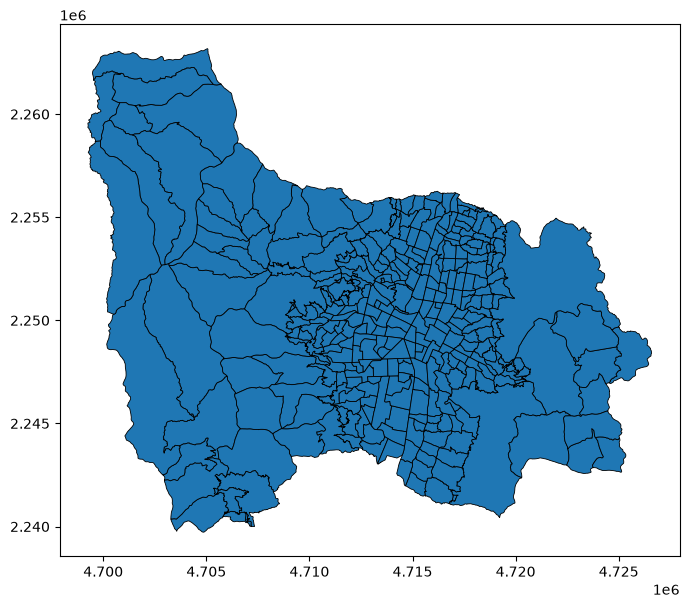

In [34]:
# Mapa medellín
barrios.plot(figsize=(8, 8), edgecolor="black", linewidth=0.6)
#, cmap="tab20"

## Etapa 3:Exploración - Capa de Comunas

Verificación de la capa comunas. 


In [28]:
print("Columnas:", list(comunas.columns))
print("\nCRS:", comunas.crs)
print("\nGeometrías son válidas:", comunas.is_valid.all())
print(f"\nCRS de barrios {barrios.crs} y CRS de comunas {comunas.crs}")

display(
    comunas.columns,
    comunas.shape
)

comunas[["codigo", "nombre"]]


Columnas: ['codigo', 'nombre', 'identifica', 'limitemuni', 'subtipo_co', 'fecha_actu', 'Shape_Leng', 'Shape_Area', 'geometry']

CRS: EPSG:9377

Geometrías son válidas: True

CRS de barrios EPSG:9377 y CRS de comunas EPSG:9377


Index(['codigo', 'nombre', 'identifica', 'limitemuni', 'subtipo_co',
       'fecha_actu', 'Shape_Leng', 'Shape_Area', 'geometry'],
      dtype='str')

(23, 9)

,codigo,nombre
0,01,Popular
1,02,Santa Cruz
2,03,Manrique
3,04,Aranjuez
4,05,Castilla
5,06,Doce de Octubre
6,07,Robledo
7,08,Villa Hermosa
8,09,Buenos Aires
9,10,La Candelaria


<Axes: >

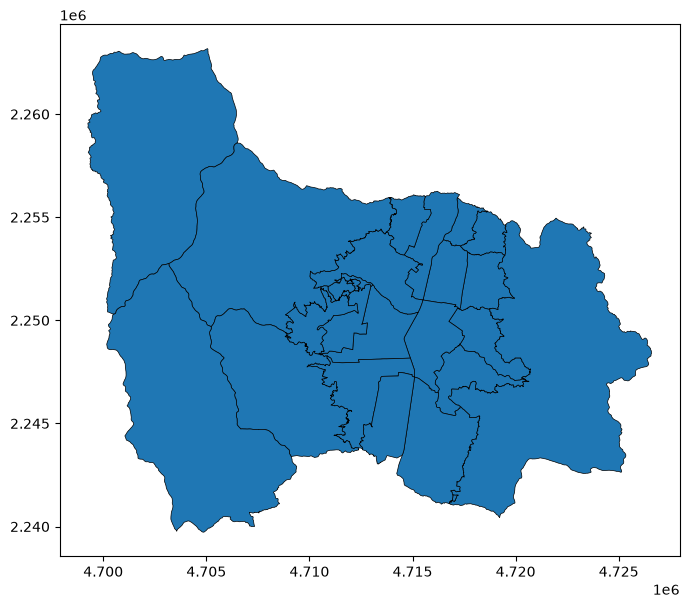

In [35]:
comunas.plot(figsize=(8, 8), edgecolor="black", linewidth=0.5 )
# cmap="tab20"


## Etapa 4: Exploración - Dataset de hurtos

* Se revisan específicamente las columnas que se usarán para el cruce
espacial: `codigo_barrio` y `codigo_comuna`. 

* **El objetivo**: formato _antes_ de limpiar nada.


In [39]:
print("Columnas relevantes para el cruce:")
print(hurtos[["nombre_barrio", "codigo_barrio", "codigo_comuna"]].head(10))

print("\nColumna codigo_barrio:", hurtos["codigo_barrio"].dtype)
print("Columna codigo_comuna:", hurtos["codigo_comuna"].dtype)

print("\nNulos en codigo_barrio:", hurtos["codigo_barrio"].isna().sum())
print("Nulos en codigo_comuna:", hurtos["codigo_comuna"].isna().sum())

print("\nColumna codigo_barrio en formato:")
print(hurtos["codigo_barrio"].dropna().unique()[:10])


Columnas relevantes para el cruce:
           nombre_barrio codigo_barrio codigo_comuna
0               El Pomar         #0306             3
1                La Rosa         #0211             2
2                La Isla         #0201             2
3              Guayaquil         #1007            10
4  Manrique Central No.1         #0409             4
5             Campo Amor         #1507            15
6               Pajarito         #0723             7
7               El Pomar         #0306             3
8     Trece de Noviembre         #0811             8
9               Aranjuez         #0413             4

Columna codigo_barrio: str
Columna codigo_comuna: object

Nulos en codigo_barrio: 0
Nulos en codigo_comuna: 0

Columna codigo_barrio en formato:
<StringArray>
['#0306', '#0211', '#0201', '#1007', '#0409', '#1507', '#0723', '#0811',
 '#0413', '#1006']
Length: 10, dtype: str


## Etapa 5: Transformación - limpieza `codigo_barrio`

El shapefile de barrios usa códigos de 4 dígitos
tipo str (`'0306'`), mientras que el dataset de hurtos viene con los codigos en formato(`'#0306'`).

**Transformación:** se elimina el `#` y se limpian espacios en ambos extremos.


In [41]:
# Shapefile: nos aseguramos de que el código quede como texto sin espacios en blanco
barrios["codigo_limpio"] = barrios["codigo"].astype(str).str.strip()

# Hurtos: quitamos el '#' inicial
hurtos["codigo_barrio_limpio"] = (
    hurtos["codigo_barrio"]
    .astype(str)
    .str.replace("#", "", regex=False)
    .str.strip()
)

# Comparación ANTES / DESPUÉS
dif = pd.DataFrame({
    "hurtos_crudo": hurtos["codigo_barrio"].head(5).values,
    "hurtos_limpio": hurtos["codigo_barrio_limpio"].head(5).values,
})
dif


,hurtos_crudo,hurtos_limpio
0,#0306,0306
1,#0211,0211
2,#0201,0201
3,#1007,1007
4,#0409,0409


## Etapa 6: Transformación - limpieza de `codigo_comuna`

El shapefile (shp) de comunas usa códigos de 2 dígitos
como str en formato (`'03'`), mientras que el dataset
de hurtos trae el código en formato (`3`).

**Transformación:** se convierte a texto y se rellena con cero a la
izquierda hasta 2 dígitos (`zfill(2)`).


In [42]:
# Shapefile: aseguramos formato de 2 dígitos como texto
comunas["codigo_limpio"] = comunas["codigo"].astype(str).str.zfill(2).str.strip()

# Hurtos: convertimos a texto y rellenamos con cero
hurtos["codigo_comuna_dd"] = (
    hurtos["codigo_comuna"].astype(str).str.zfill(2).str.strip()
)

comparacion_comuna = pd.DataFrame({
    "hurtos_crudo": hurtos["codigo_comuna"].head(5).values,
    "hurtos_limpio": hurtos["codigo_comuna_dd"].head(5).values,
})
comparacion_comuna


,hurtos_crudo,hurtos_limpio
0,3,03
1,2,02
2,2,02
3,10,10
4,4,04


## Etapa 7: Validación cruce: Hurtos <-> Barrios

Antes de unir los datos, se valida qué porcentaje de registros de hurto
tiene un código de barrio que existe en el shapefile. Esto se hace
comparando los conjuntos de códigos únicos de ambas fuentes.


In [46]:
codigos_shp_barrio = set(barrios["codigo_limpio"])
codigos_hurtos_barrio = set(hurtos["codigo_barrio_limpio"].dropna())

# Códigos que aparecen en hurtos pero NO existen en el shapefile
sin_match_barrio = codigos_hurtos_barrio - codigos_shp_barrio

# Cuántos REGISTROS (no códigos únicos) se ven afectados
n_afectados_barrio = hurtos["codigo_barrio_limpio"].isin(sin_match_barrio).sum()
pct_afectados_barrio = 100 * n_afectados_barrio / len(hurtos)
pct_exito_barrio = 100 - pct_afectados_barrio

print(f"Códigos de barrio únicos en hurtos.......: {len(codigos_hurtos_barrio)}")
print(f"Códigos de barrio únicos en shapefile....: {len(codigos_shp_barrio)}")
print(f"Códigos en hurtos sin match en shapefile.: {len(sin_match_barrio)}")
print()
print(f"Registros de hurto CRUZADOS con éxito....: {len(hurtos) - n_afectados_barrio} ({pct_exito_barrio:.2f}%)")
print(f"Registros de hurto SIN cruzar............: {n_afectados_barrio} ({pct_afectados_barrio:.2f}%)")

if sin_match_barrio:
    print("\nEjemplos de códigos sin match:", list(sin_match_barrio)[:4])


Códigos de barrio únicos en hurtos.......: 336
Códigos de barrio únicos en shapefile....: 332
Códigos en hurtos sin match en shapefile.: 12

Registros de hurto CRUZADOS con éxito....: 84553 (97.85%)
Registros de hurto SIN cruzar............: 1857 (2.15%)

Ejemplos de códigos sin match: ['SIN DATO 6 DOCE DE OCTUBRE', 'SIN DATO 60 SAN CRISTOBAL', 'SIN DATO 13 SAN JAVIER', 'SIN DATO 3 MANRIQUE']


## Etapa 8: Validación cruce: Hurtos <-> Comunas

Mismo procedimiento de la Etapa 7, ahora a nivel de comuna.


In [50]:
codigos_shp_comuna = set(comunas["codigo_limpio"])
codigos_hurtos_comuna = set(hurtos["codigo_comuna_dd"].dropna())

sin_match_comuna = codigos_hurtos_comuna - codigos_shp_comuna

n_afectados_comuna = hurtos["codigo_comuna_dd"].isin(sin_match_comuna).sum()
pct_afectados_comuna = 100 * n_afectados_comuna / len(hurtos)
pct_exito_comuna = 100 - pct_afectados_comuna

print(f"Códigos de comuna únicos en hurtos       : {len(codigos_hurtos_comuna)}")
print(f"Códigos de comuna únicos en shapefile    : {len(codigos_shp_comuna)}")
print(f"Códigos en hurtos sin match en shapefile : {len(sin_match_comuna)}")
print()
print(f"Registros de hurto CRUZADOS con éxito     : {len(hurtos) - n_afectados_comuna} ({pct_exito_comuna:.2f}%)")
print(f"Registros de hurto SIN cruzar             : {n_afectados_comuna} ({pct_afectados_comuna:.2f}%)")

if sin_match_comuna:
    print("\nCódigos sin match:", sorted(sin_match_comuna))


Códigos de comuna únicos en hurtos       : 22
Códigos de comuna únicos en shapefile    : 23
Códigos en hurtos sin match en shapefile : 1

Registros de hurto CRUZADOS con éxito     : 84678 (98.00%)
Registros de hurto SIN cruzar             : 1732 (2.00%)

Códigos sin match: ['SIN DATO']


## Etapa 9: Unión - conteo de hurtos por Barrio

Se agregan (cuentan) los hurtos por `codigo_barrio_limpio` y se unen
al shapefile de barrios mediante un `merge` (unión por atributo, no
espacial: se hace por el código en común, no por coordenadas).

Se usa `how="left"` para conservar **todos** los barrios, incluso los
que no tuvieron ningún hurto (quedarán en 0).


In [51]:
conteo_barrio = (
    hurtos.groupby("codigo_barrio_limpio")
    .size()
    .reset_index(name="n_hurtos")
)

barrios_hurtos = barrios.merge(
    conteo_barrio,
    left_on="codigo_limpio",
    right_on="codigo_barrio_limpio",
    how="left",
)
barrios_hurtos["n_hurtos"] = barrios_hurtos["n_hurtos"].fillna(0)

print(f"Barrios totales                : {len(barrios_hurtos)}")
print(f"Barrios con al menos 1 hurto   : {(barrios_hurtos['n_hurtos'] > 0).sum()}")
print(f"Barrios sin ningún hurto       : {(barrios_hurtos['n_hurtos'] == 0).sum()}")
print(f"Total de hurtos sumados        : {barrios_hurtos['n_hurtos'].sum():.0f}  "
      f"(debe ser cercano a {len(hurtos)})")

barrios_hurtos.sort_values("n_hurtos", ascending=False)[["nombre", "n_hurtos"]].head(10)


Barrios totales                : 332
Barrios con al menos 1 hurto   : 324
Barrios sin ningún hurto       : 8
Total de hurtos sumados        : 84553  (debe ser cercano a 86410)


,nombre,n_hurtos
47,Prado,2408.0
145,Boston,1820.0
257,La Candelaria,1758.0
169,Manrique Central No.1,1325.0
297,Castilla,1239.0
28,Buenos Aires,1155.0
236,San Miguel,1028.0
83,Manrique Central No.2,1011.0
76,Campo Valdés No.1,984.0
102,Belén,982.0


<Axes: >

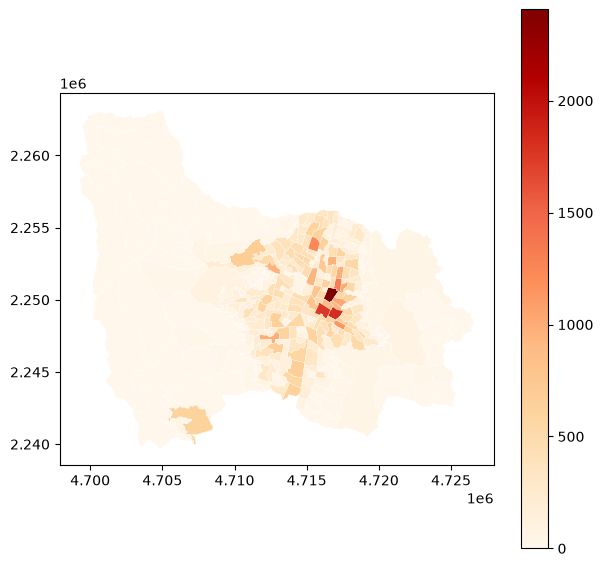

In [52]:
# Mapa rápido de conteo de hurtos por barrio
barrios_hurtos.plot(
    column="n_hurtos", cmap="OrRd", legend=True, figsize=(7, 7),
    edgecolor="white", linewidth=0.2
)


## Etapa 10: Unión - conteo de hurtos por Comuna

Mismo procedimiento de la Etapa 9, ahora a nivel de comuna. Esta es la
segunda escala espacial de tu análisis MAUP (barrio vs. comuna).


In [53]:
conteo_comuna = (
    hurtos.groupby("codigo_comuna_dd")
    .size()
    .reset_index(name="n_hurtos")
)

comunas_hurtos = comunas.merge(
    conteo_comuna,
    left_on="codigo_limpio",
    right_on="codigo_comuna_dd",
    how="left",
)
comunas_hurtos["n_hurtos"] = comunas_hurtos["n_hurtos"].fillna(0)

print(f"Comunas totales                : {len(comunas_hurtos)}")
print(f"Comunas con al menos 1 hurto   : {(comunas_hurtos['n_hurtos'] > 0).sum()}")
print(f"Total de hurtos sumados        : {comunas_hurtos['n_hurtos'].sum():.0f}  "
      f"(debe ser cercano a {len(hurtos)})")

comunas_hurtos.sort_values("n_hurtos", ascending=False)[["nombre", "n_hurtos"]]


Comunas totales                : 23
Comunas con al menos 1 hurto   : 21
Total de hurtos sumados        : 84678  (debe ser cercano a 86410)


,nombre,n_hurtos
9,La Candelaria,14415.0
3,Aranjuez,8583.0
6,Robledo,7615.0
4,Castilla,7196.0
8,Buenos Aires,6361.0
14,Belén,5983.0
10,Laureles Estadio,5872.0
7,Villa Hermosa,4686.0
2,Manrique,4069.0
11,La América,3913.0


<Axes: >

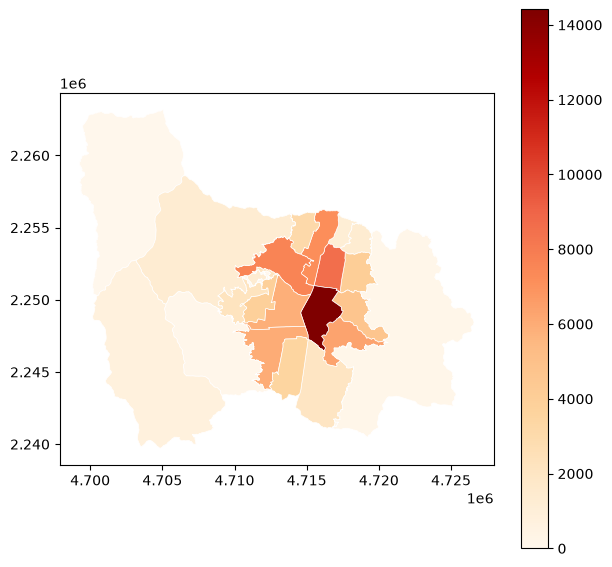

In [54]:
comunas_hurtos.plot(
    column="n_hurtos", cmap="OrRd", legend=True, figsize=(7, 7),
    edgecolor="white", linewidth=0.5
)


## Etapa 11 — Comparación de escalas (evidencia visual del MAUP)

Se colocan lado a lado el mapa por barrio y el mapa por comuna, usando
la **misma paleta de colores**, para observar cómo cambia la lectura
visual del fenómeno según la unidad espacial de agregación.


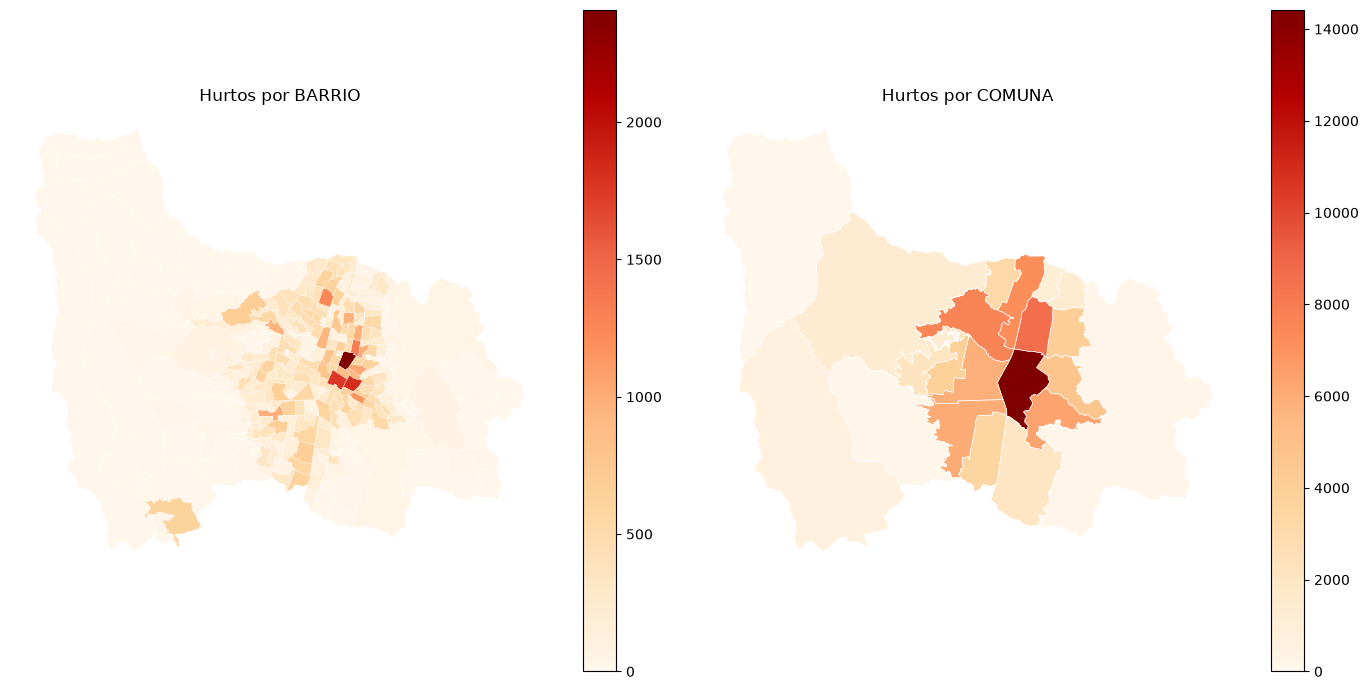

In [55]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(14, 7))

barrios_hurtos.plot(column="n_hurtos", cmap="OrRd", legend=True, ax=axes[0],
                     edgecolor="white", linewidth=0.2)
axes[0].set_title("Hurtos por BARRIO")
axes[0].axis("off")

comunas_hurtos.plot(column="n_hurtos", cmap="OrRd", legend=True, ax=axes[1],
                     edgecolor="white", linewidth=0.5)
axes[1].set_title("Hurtos por COMUNA")
axes[1].axis("off")

plt.tight_layout()
plt.show()


## Etapa 12 — Resumen final de validación

Esta celda consolida los resultados clave de todo el proceso: útil para
copiar directamente a la Presentación 1.


In [56]:
print("=" * 60)
print("RESUMEN DE VALIDACIÓN — LISTO PARA PRESENTACIÓN 1")
print("=" * 60)
print(f"Registros de hurto totales           : {len(hurtos)}")
print(f"Polígonos de barrio                  : {len(barrios)}")
print(f"Polígonos de comuna                  : {len(comunas)}")
print(f"CRS de las capas espaciales          : {barrios.crs}")
print()
print(f"% de hurtos cruzados con barrio      : {pct_exito_barrio:.2f}%")
print(f"% de hurtos cruzados con comuna      : {pct_exito_comuna:.2f}%")
print()
if pct_exito_barrio > 95 and pct_exito_comuna > 95:
    print("✅ El cruce es sólido. Los datos están listos para avanzar")
    print("   a la fase de redacción y construcción de la Presentación 1.")
else:
    print("⚠️  Hay un porcentaje relevante de registros sin cruzar.")
    print("   Revisa las Etapas 7 y 8 para identificar la causa antes de continuar.")


RESUMEN DE VALIDACIÓN — LISTO PARA PRESENTACIÓN 1
Registros de hurto totales           : 86410
Polígonos de barrio                  : 332
Polígonos de comuna                  : 23
CRS de las capas espaciales          : EPSG:9377

% de hurtos cruzados con barrio      : 97.85%
% de hurtos cruzados con comuna      : 98.00%

✅ El cruce es sólido. Los datos están listos para avanzar
   a la fase de redacción y construcción de la Presentación 1.
